# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement

✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.
>

> **Your answer:** *The objective of this project is to accurately classify breast masses as either malignant or benign based on thirty clinical and structural nucleus measurements extracted from digitized fine-needle aspirate (FNA) images. This is modeled as a supervised binary classification problem where a false negative error—misclassifying a malignant tumor as benign—is far more costly because a delayed diagnosis can be life-threatening for the patient. To evaluate model success robustly, we will prioritize optimizing the recall/sensitivity of the malignant class to minimize these critical false negatives while maintaining high overall ROC-AUC and classification accuracy.*

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)


try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).

> *Using your own data?* Only this cell changes. For an ARFF file use `scipy.io.arff.loadarff`, and keep the rest of the workbook as is.

> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [7]:
# TODO: load the dataset and copy its DataFrame into df

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")


Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [8]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows

print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes.value_counts())

print("\nFirst five rows:")
display(df.head())


Dataset shape: (569, 31)

Data types:
float64    30
int64       1
Name: count, dtype: int64

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [9]:
# TODO: class counts and percentages

class_counts = df["target"].value_counts().sort_index()
class_percentages = df["target"].value_counts(normalize=True).sort_index() * 100

print("Class counts:")
print(class_counts.rename(index={0: "Malignant", 1: "Benign"}))

print("\nClass percentages:")
print(
    class_percentages.rename(index={0: "Malignant", 1: "Benign"})
    .round(2)
)


Class counts:
target
Malignant    212
Benign       357
Name: count, dtype: int64

Class percentages:
target
Malignant    37.26
Benign       62.74
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [10]:
# TODO: describe().T, then the 10 largest skewness values

print("Summary Statistics:")
display(df.describe().T)

skewness = df.drop(columns="target").skew()
top_skewed = skewness.reindex(
    skewness.abs().sort_values(ascending=False).head(10).index
)

print("\n10 Most Skewed Features:")
display(top_skewed.to_frame(name="Skewness"))


Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



10 Most Skewed Features:


,Skewness
area error,5.447186
concavity error,5.110463
fractal dimension error,3.923969
perimeter error,3.443615
radius error,3.088612
smoothness error,2.314450
symmetry error,2.195133
compactness error,1.902221
worst area,1.859373
worst fractal dimension,1.662579


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [11]:
# TODO: correlation with target, sorted

correlations = (
    df.corr(numeric_only=True)["target"]
    .drop("target")
    .sort_values()
)

print("Five Most Negative Correlations:")
display(correlations.head(5).to_frame(name="Correlation"))

print("\nFive Most Positive Correlations:")
display(
    correlations.tail(5)
    .sort_values(ascending=False)
    .to_frame(name="Correlation")
)


Five Most Negative Correlations:


,Correlation
worst concave points,-0.793566
worst perimeter,-0.782914
mean concave points,-0.776614
worst radius,-0.776454
mean perimeter,-0.742636



Five Most Positive Correlations:


,Correlation
smoothness error,0.067016
mean fractal dimension,0.012838
texture error,0.008303
symmetry error,0.006522
fractal dimension error,-0.077972


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** *The dataset contains more benign cases than malignant cases, so accuracy alone may not fully reflect model performance. Recall for the malignant class and ROC-AUC should also be considered to evaluate the model's ability to detect cancer. Highly skewed features may benefit from transformations, although scaling and transformations should be selected based on the model and data distribution.*

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

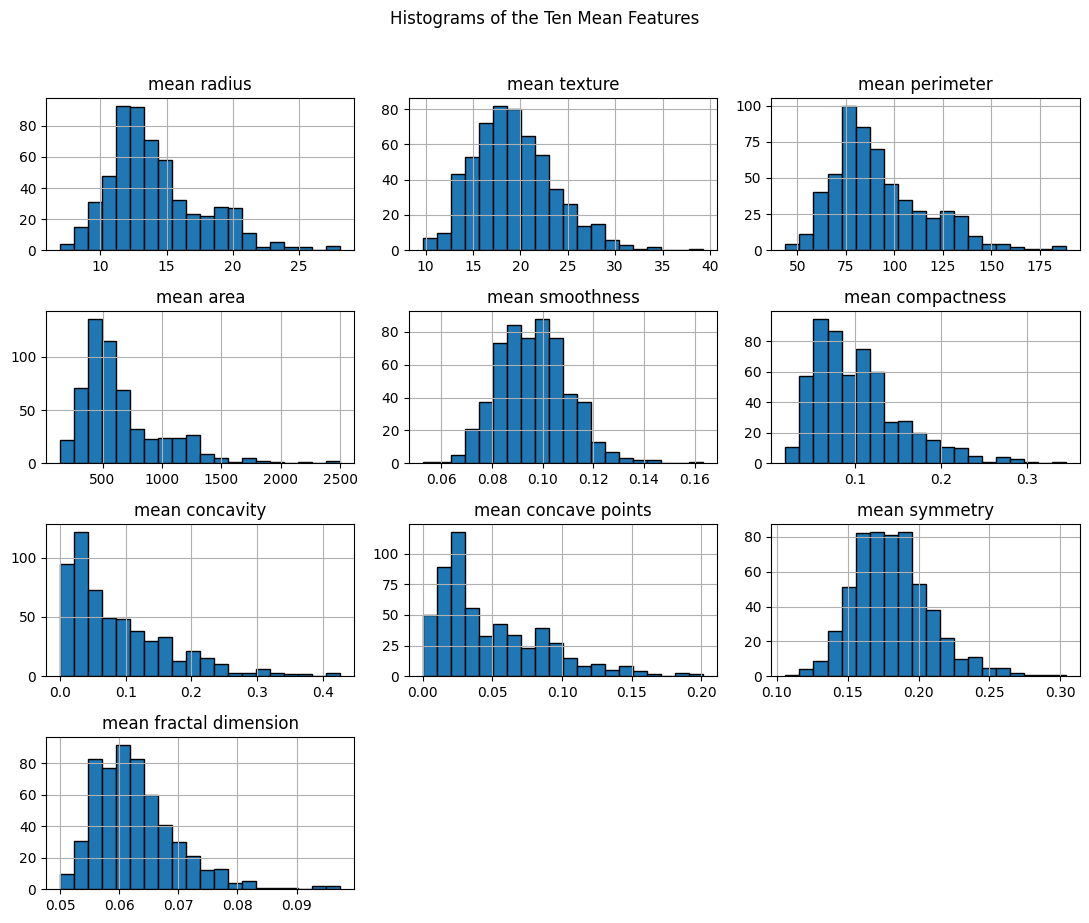

In [17]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)

df.filter(like="mean").hist(
    figsize=(11, 9),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Histograms of the Ten Mean Features", y=1.02)
plt.tight_layout()
plt.show()



**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

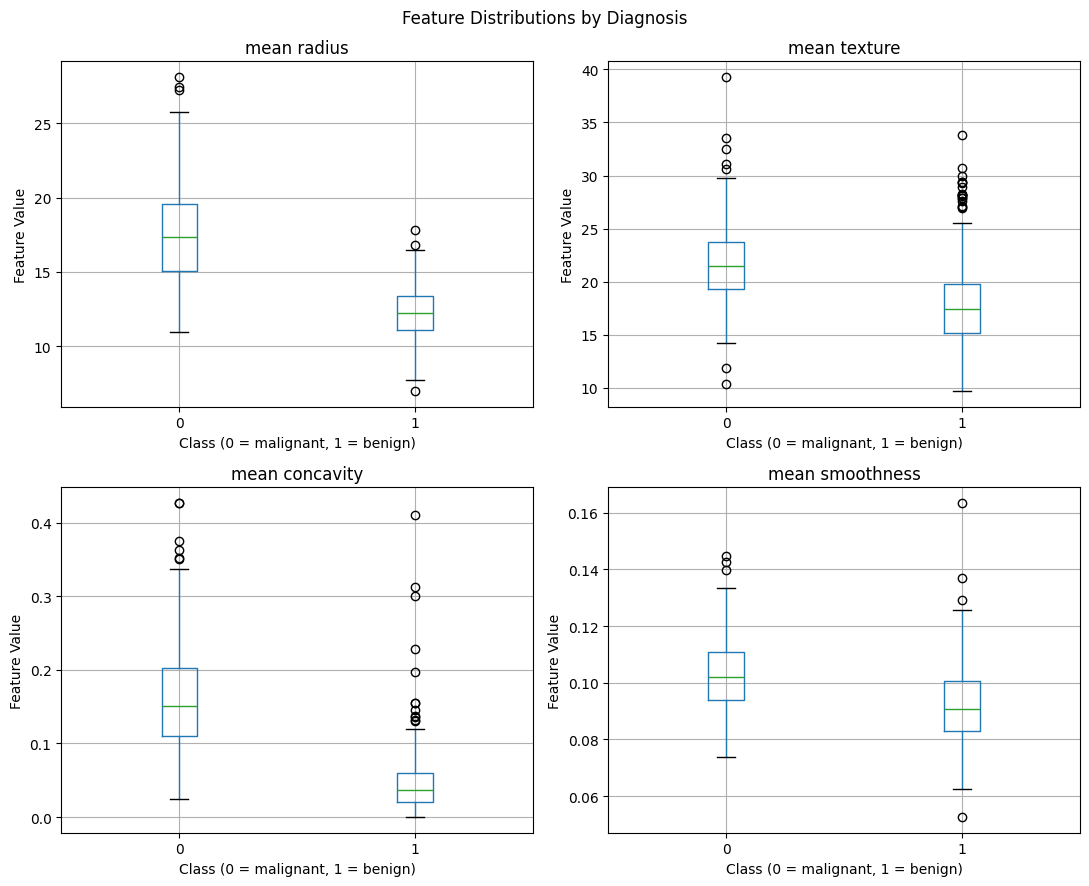

In [20]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, feature in zip(axes.flatten(), features):
    df.boxplot(column=feature, by="target", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("Class (0 = malignant, 1 = benign)")
    ax.set_ylabel("Feature Value")

plt.suptitle("Feature Distributions by Diagnosis")
plt.tight_layout()
plt.show()


**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

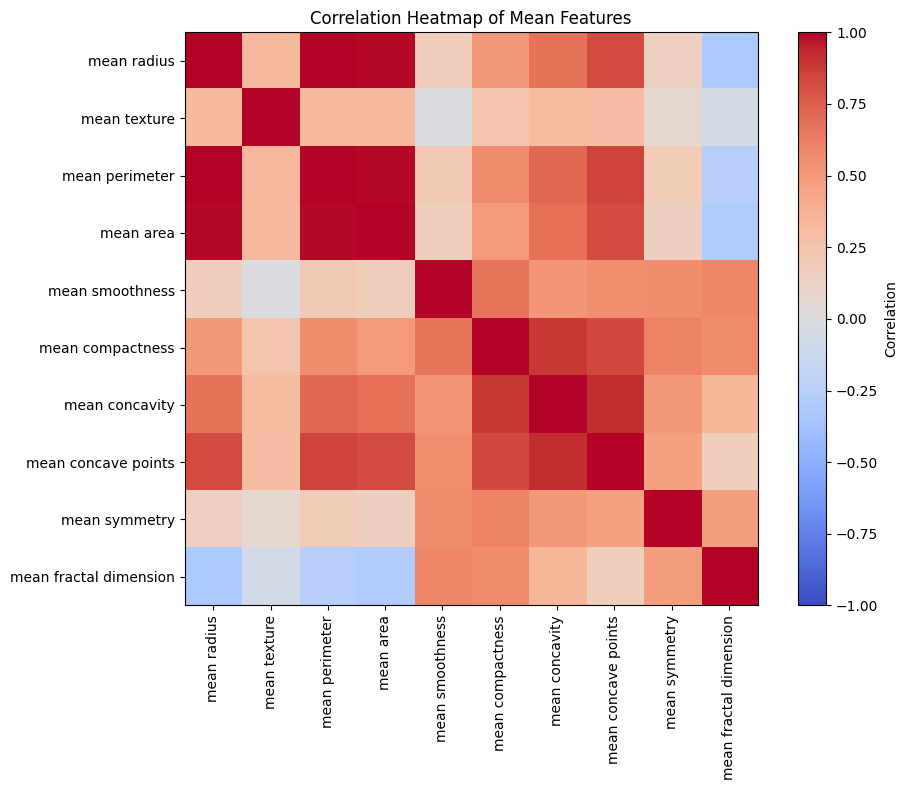

In [21]:
# TODO: correlation matrix of the "mean" features drawn with imshow

mean_features = df.filter(like="mean")
corr_matrix = mean_features.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)
plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Correlation Heatmap of Mean Features")
plt.tight_layout()
plt.show()


**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

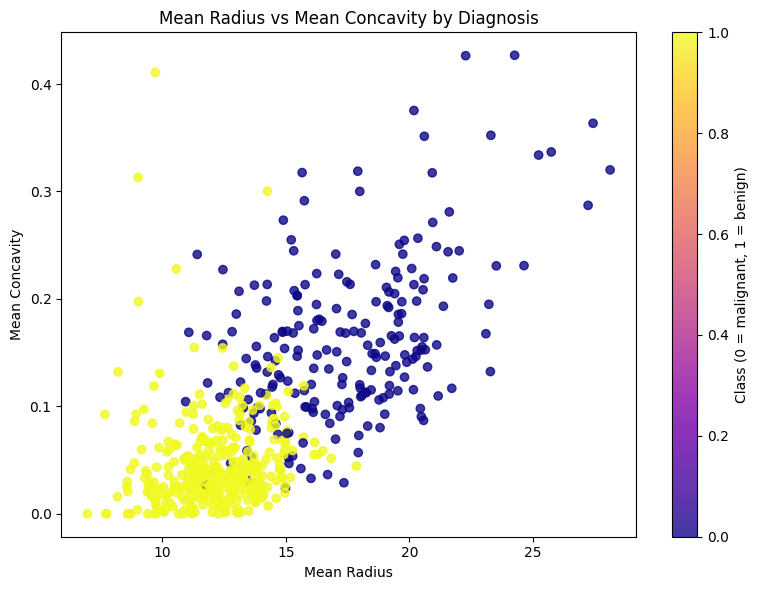

In [28]:
# TODO: coloured scatter plot with axis labels and a colourbar

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="plasma",
    alpha=0.8
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs Mean Concavity by Diagnosis")
plt.colorbar(
    scatter,
    label="Class (0 = malignant, 1 = benign)"
)

plt.tight_layout()
plt.show()


✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** *Features such as mean radius, mean perimeter, and mean area appear redundant because they are strongly correlated with one another. Mean radius and mean concavity may help separate malignant from benign cases, as malignant cases generally show higher values for these measurements. However, no single feature perfectly separates the two classes, so using multiple features together is more reliable.*

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [29]:
# TODO: total missing values and duplicated rows

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]


Total missing values: 0
Duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [30]:
# TODO: IQR outlier count per feature

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outlier_counts = (
    (X < (Q1 - 1.5 * IQR)) |
    (X > (Q3 + 1.5 * IQR))
).sum()

print("Ten features with the most outliers:")
display(
    outlier_counts.sort_values(ascending=False)
    .head(10)
    .to_frame(name="Outlier Count")
)


Ten features with the most outliers:


,Outlier Count
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** *I would not automatically delete the outlying rows because extreme measurements may represent genuine characteristics of malignant or benign tumors. Removing them could discard important diagnostic information and reduce model performance. I would investigate the outliers first and only correct or remove observations if there is evidence of data-entry errors or invalid measurements.*

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [31]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95

corr_abs = X.corr().abs()
upper = corr_abs.where(
    np.triu(np.ones(corr_abs.shape), k=1).astype(bool)
)

for column in upper.columns:
    correlated = upper[column][upper[column] > 0.95]
    for feature, correlation in correlated.items():
        print(f"{feature} <-> {column}: {correlation:.3f}")

mean radius <-> mean perimeter: 0.998
mean radius <-> mean area: 0.987
mean perimeter <-> mean area: 0.987
radius error <-> perimeter error: 0.973
radius error <-> area error: 0.952
mean radius <-> worst radius: 0.970
mean perimeter <-> worst radius: 0.969
mean area <-> worst radius: 0.963
mean radius <-> worst perimeter: 0.965
mean perimeter <-> worst perimeter: 0.970
mean area <-> worst perimeter: 0.959
worst radius <-> worst perimeter: 0.994
mean area <-> worst area: 0.959
worst radius <-> worst area: 0.984
worst perimeter <-> worst area: 0.978


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [32]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

kbest_scores = pd.Series(
    selector.scores_,
    index=X.columns
).sort_values(ascending=False)

print("Top 10 features by SelectKBest:")
display(kbest_scores.head(10).to_frame(name="F-Score"))

Top 10 features by SelectKBest:


,F-Score
worst concave points,964.385393
worst perimeter,897.944219
mean concave points,861.676020
worst radius,860.781707
mean perimeter,697.235272
worst area,661.600206
mean radius,646.981021
mean area,573.060747
mean concavity,533.793126
worst concavity,436.691939


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [33]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features

scaler_rfe = StandardScaler()
X_scaled_rfe = scaler_rfe.fit_transform(X)

rfe = RFE(
    estimator=LogisticRegression(max_iter=5000, random_state=7),
    n_features_to_select=10
)

rfe.fit(X_scaled_rfe, y)
rfe_features = X.columns[rfe.support_].tolist()

print("10 features selected by RFE:")
print(rfe_features)

10 features selected by RFE:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

Top 10 features by ExtraTrees importance:


,Importance
worst concave points,0.111981
worst radius,0.086108
worst area,0.083990
mean concave points,0.075045
worst perimeter,0.074022
mean perimeter,0.061303
mean radius,0.058711
mean concavity,0.055757
mean area,0.051197
worst concavity,0.047384


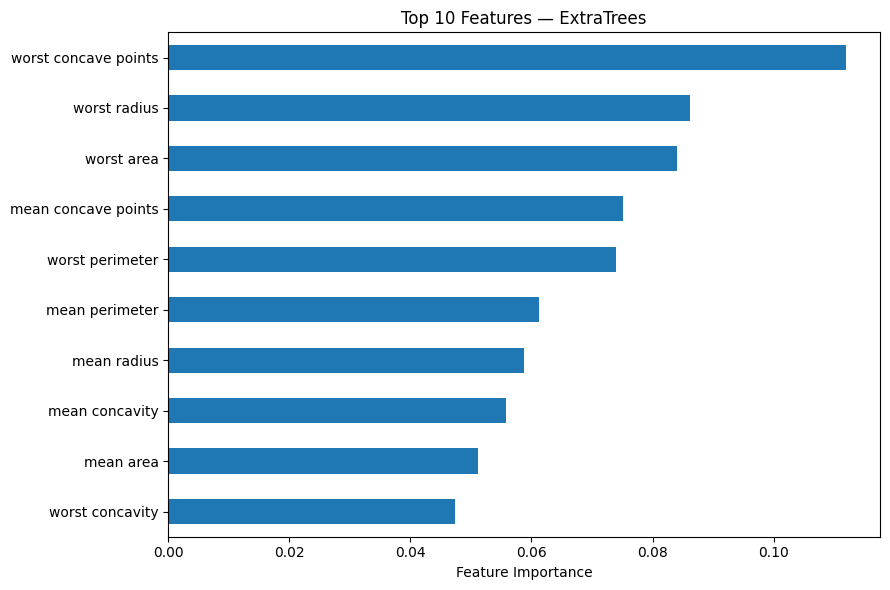

In [34]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10

extra_trees = ExtraTreesClassifier(
    n_estimators=200,
    random_state=7
)

extra_trees.fit(X, y)

imp = pd.Series(
    extra_trees.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 10 features by ExtraTrees importance:")
display(imp.head(10).to_frame(name="Importance"))

imp.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.xlabel("Feature Importance")
plt.title("Top 10 Features — ExtraTrees")
plt.tight_layout()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [36]:
# TODO: vote across the three methods

kbest_features = kbest_scores.head(10).index.tolist()
extra_trees_features = imp.head(10).index.tolist()

votes = pd.Series(0, index=X.columns, dtype=int)

for feature in kbest_features:
    votes[feature] += 1

for feature in rfe_features:
    votes[feature] += 1

for feature in extra_trees_features:
    votes[feature] += 1

selected = votes[votes >= 2].index.tolist()

print("Selected features (at least two votes):")
print(selected)
print("Number of selected features:", len(selected))

Selected features (at least two votes):
['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']
Number of selected features: 10


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [37]:
# TODO: train_test_split with stratify=y

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=7,
    stratify=y
)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [38]:
# TODO: fit both scalers on X_train and print the verifying statistics

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X_train_standard = standard_scaler.fit_transform(X_train)
X_train_minmax = minmax_scaler.fit_transform(X_train)

standard_df = pd.DataFrame(
    X_train_standard,
    columns=X_train.columns,
    index=X_train.index
)

minmax_df = pd.DataFrame(
    X_train_minmax,
    columns=X_train.columns,
    index=X_train.index
)

print("StandardScaler — first four features")
print("Means:")
display(standard_df.iloc[:, :4].mean().round(4))

print("Standard deviations:")
display(standard_df.iloc[:, :4].std(ddof=0).round(4))

print("\nMinMaxScaler — first four features")
print("Minimums:")
display(minmax_df.iloc[:, :4].min().round(4))

print("Maximums:")
display(minmax_df.iloc[:, :4].max().round(4))

StandardScaler — first four features
Means:


,0
mean radius,0.0
mean texture,-0.0
mean perimeter,-0.0
mean area,-0.0


Standard deviations:


,0
mean radius,1.0
mean texture,1.0
mean perimeter,1.0
mean area,1.0



MinMaxScaler — first four features
Minimums:


,0
mean radius,0.0
mean texture,0.0
mean perimeter,0.0
mean area,0.0


Maximums:


,0
mean radius,1.0
mean texture,1.0
mean perimeter,1.0
mean area,1.0


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [39]:
# TODO: fit PCA on standardised training data and use cumulative explained variance

pca = PCA()
pca.fit(X_train_standard)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components needed for 95% variance:", n_components_95)
print(
    "Cumulative explained variance:",
    round(cumulative_variance[n_components_95 - 1], 4)
)

Components needed for 95% variance: 10
Cumulative explained variance: 0.956


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [40]:
# TODO: define the six classification models

seed = 7

models = {
    "LR": LogisticRegression(max_iter=5000, random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed)
}

kfold = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=seed
)

print("Models defined:", list(models.keys()))

Models defined: ['LR', 'LDA', 'KNN', 'CART', 'NB', 'SVM']


**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [45]:
# D.2: Evaluate models on raw and scaled training features

def spot_check(models, X_data, scale=False):
    results = {}

    for name, model in models.items():
        steps = []

        if scale:
            steps.append(("scale", StandardScaler()))

        steps.append(("model", model))
        pipeline = Pipeline(steps)

        scores = cross_val_score(
            pipeline,
            X_data,
            y_train,
            cv=kfold,
            scoring="accuracy"
        )

        results[name] = scores

    return results


raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

summary = pd.DataFrame({
    "raw": {
        name: scores.mean()
        for name, scores in raw_results.items()
    },
    "scaled": {
        name: scores.mean()
        for name, scores in scaled_results.items()
    }
})

display(summary.sort_values("scaled", ascending=False).round(4))

,raw,scaled
LR,0.9538,0.9823
SVM,0.8987,0.9758
KNN,0.9229,0.9649
LDA,0.9472,0.9472
NB,0.9341,0.9320
CART,0.9276,0.9276


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** *Feature scaling improves the performance of models such as KNN, SVM, and Logistic Regression because they are sensitive to differences in feature scales. Scaling puts features on a comparable range, helping these models perform better. Decision trees are generally less affected by scaling because they use feature-based splitting rules.*

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [46]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results

selected_results = spot_check(
    models,
    X_train[selected],
    scale=True
)

selected_summary = pd.Series({
    name: scores.mean()
    for name, scores in selected_results.items()
}, name="selected_scaled")

comparison = pd.concat(
    [summary["scaled"], selected_summary],
    axis=1
)

comparison.columns = [
    "all_features_scaled",
    "selected_features_scaled"
]

display(
    comparison.sort_values(
        "selected_features_scaled",
        ascending=False
    ).round(4)
)

,all_features_scaled,selected_features_scaled
LR,0.9823,0.9604
SVM,0.9758,0.9539
NB,0.9320,0.9517
LDA,0.9472,0.9430
KNN,0.9649,0.9428
CART,0.9276,0.9210


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

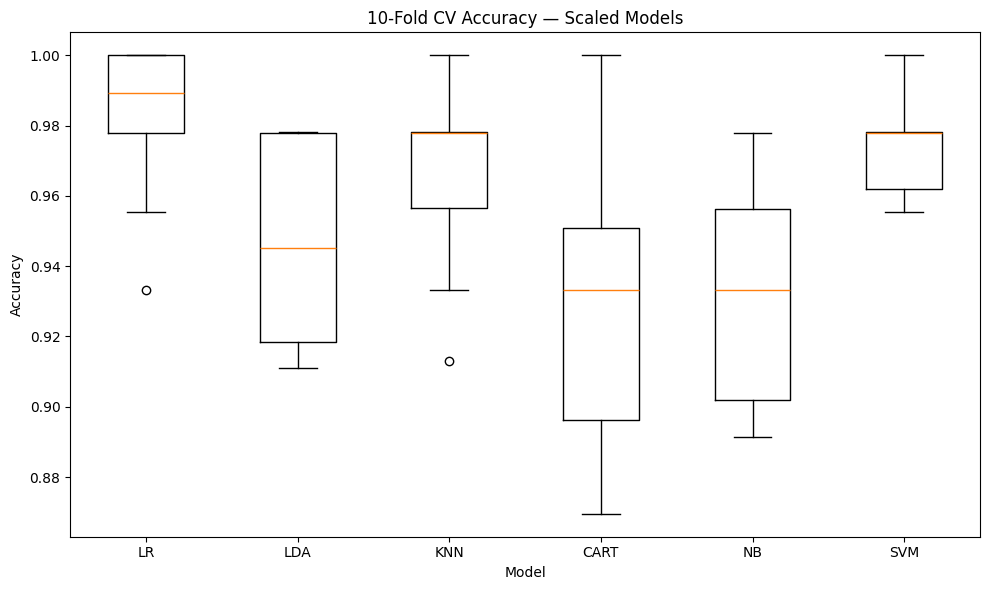

In [47]:
# TODO: box plot of the 10 fold scores per model

plt.figure(figsize=(10, 6))

plt.boxplot(
    [scaled_results[name] for name in models],
    tick_labels=list(models.keys())
)

plt.title("10-Fold CV Accuracy — Scaled Models")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [48]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)

best_scaled_name = summary["scaled"].idxmax()
best_scaled_model = models[best_scaled_name]

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "malignant_recall": make_scorer(
        recall_score,
        pos_label=0
    )
}

best_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", best_scaled_model)
])

cv_metrics = cross_validate(
    best_pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring=scoring
)

metrics_summary = pd.DataFrame({
    metric: cv_metrics[f"test_{metric}"]
    for metric in scoring
}).agg(["mean", "std"]).T

print("Best scaled model:", best_scaled_name)
print("Mean and standard deviation across 10 folds:")
display(metrics_summary.round(4))

Best scaled model: LR
Mean and standard deviation across 10 folds:


,mean,std
accuracy,0.9823,0.0229
roc_auc,0.9922,0.0113
malignant_recall,0.9647,0.0496


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [49]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]

svm_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC())
])

svm_param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

svm_search = GridSearchCV(
    svm_pipeline,
    svm_param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

svm_search.fit(X_train, y_train)

print("Best SVM parameters:", svm_search.best_params_)
print("Best SVM CV accuracy:", round(svm_search.best_score_, 4))

Best SVM parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best SVM CV accuracy: 0.9802


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [50]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]

knn_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

knn_search = GridSearchCV(
    knn_pipeline,
    knn_param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

knn_search.fit(X_train, y_train)

print("Best KNN parameters:", knn_search.best_params_)
print("Best KNN CV accuracy:", round(knn_search.best_score_, 4))

Best KNN parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best KNN CV accuracy: 0.9693


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [51]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier

ensemble_models = {
    "RF": RandomForestClassifier(
        n_estimators=200,
        random_state=seed
    ),
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=seed
    ),
    "GradientBoosting": GradientBoostingClassifier(
        random_state=seed
    ),
    "AdaBoost": AdaBoostClassifier(
        random_state=seed
    )
}

ensemble_results = spot_check(
    ensemble_models,
    X_train,
    scale=False
)

ensemble_summary = pd.Series({
    name: scores.mean()
    for name, scores in ensemble_results.items()
}, name="Mean CV Accuracy")

display(ensemble_summary.sort_values(ascending=False).round(4))

,Mean CV Accuracy
ExtraTrees,0.9714
GradientBoosting,0.9670
RF,0.9648
AdaBoost,0.9626


In [53]:
# Hard Voting Classifier using tuned SVM, tuned KNN, and Random Forest

voting_model = VotingClassifier(
    estimators=[
        ("svm", svm_search.best_estimator_),
        ("knn", knn_search.best_estimator_),
        ("rf", RandomForestClassifier(
            n_estimators=200,
            random_state=seed
        ))
    ],
    voting="hard"
)

voting_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", voting_model)
])

voting_scores = cross_val_score(
    voting_pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

print("Voting Classifier mean CV accuracy:", round(voting_scores.mean(), 4))

Voting Classifier mean CV accuracy: 0.9781


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [54]:
# TODO: leaderboard Series

leaderboard = pd.Series({
    "Tuned SVM": svm_search.best_score_,
    "Tuned KNN": knn_search.best_score_,
    "Random Forest": ensemble_results["RF"].mean(),
    "Extra Trees": ensemble_results["ExtraTrees"].mean(),
    "Gradient Boosting": ensemble_results["GradientBoosting"].mean(),
    "AdaBoost": ensemble_results["AdaBoost"].mean(),
    "Voting Classifier": voting_scores.mean()
}, name="Mean CV Accuracy").sort_values(ascending=False)

display(leaderboard.round(4).to_frame())

,Mean CV Accuracy
Tuned SVM,0.9802
Voting Classifier,0.9781
Extra Trees,0.9714
Tuned KNN,0.9693
Gradient Boosting,0.9670
Random Forest,0.9648
AdaBoost,0.9626


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

In [57]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix

# E.5: Fit the winning model and evaluate it on the test set

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Select the best model from the leaderboard
candidate_models = {
    "Tuned SVM": svm_search.best_estimator_,
    "Tuned KNN": knn_search.best_estimator_,
    "Random Forest": ensemble_models["RF"],
    "Extra Trees": ensemble_models["ExtraTrees"],
    "Gradient Boosting": ensemble_models["GradientBoosting"],
    "AdaBoost": ensemble_models["AdaBoost"],
    "Voting Classifier": voting_pipeline
}

winner_name = leaderboard.idxmax()
winner = candidate_models[winner_name]

# Train using the full training set
winner.fit(X_train, y_train)

# Predict on the untouched test set
y_pred = winner.predict(X_test)

# Display results
print("Winning model:", winner_name)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Malignant", "Benign"],
    zero_division=0
))

print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)

display(pd.DataFrame(
    cm,
    index=["Actual Malignant", "Actual Benign"],
    columns=["Predicted Malignant", "Predicted Benign"]
))

Winning model: Tuned SVM
Test accuracy: 0.9649

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.95      0.95        42
      Benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114

Confusion Matrix:


,Predicted Malignant,Predicted Benign
Actual Malignant,40,2
Actual Benign,2,70


**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [58]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test

import joblib

model_path = "best_breast_cancer_model.joblib"

joblib.dump(winner, model_path)
loaded_model = joblib.load(model_path)

original_predictions = winner.predict(X_test.iloc[:5])
loaded_predictions = loaded_model.predict(X_test.iloc[:5])

print("Original predictions:", original_predictions)
print("Reloaded predictions:", loaded_predictions)
print("Actual labels:", y_test.iloc[:5].to_numpy())

print(
    "Predictions match:",
    np.array_equal(original_predictions, loaded_predictions)
)

Original predictions: [0 0 1 0 1]
Reloaded predictions: [0 0 1 0 1]
Actual labels: [0 0 1 0 1]
Predictions match: True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

Here are concise answers you can copy into your Google Colab reflection section, mate.

### 1. Leakage

Feature selection using the whole dataset can cause data leakage because information from the validation folds influences which features are selected, potentially inflating cross-validation scores. I would fix this by placing feature selection inside a `Pipeline` so it is fitted only on each training fold during cross-validation.

### 2. Metric choice

I would report malignant recall and ROC-AUC alongside accuracy to the clinician. Malignant recall measures how many actual malignant cases are correctly detected, while accuracy alone can hide missed cancer cases, especially when the classes are imbalanced.

### 3. Model choice

If two models differ by only 0.3% in cross-validation accuracy, I would compare their variation across folds, interpretability, and training cost. I would prefer the more consistent and interpretable model if its performance is similar, especially in a medical setting where understanding predictions is important.

### 4. Generalization

With a much smaller dataset, results would be less reliable and more sensitive to individual observations, so I would use careful cross-validation and report uncertainty. With a more imbalanced dataset, I would focus more on malignant recall, precision, and ROC-AUC rather than accuracy alone.

### 5. Extension

I would repeat the workflow using another classification dataset, such as one loaded from an ARFF file. I would change the data-loading step, identify the target column, and check for missing values, categorical features, and class imbalance. The preprocessing, feature selection, model comparison, and evaluation steps would then be adapted to the new dataset.

In [60]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
